# Turbofan engine remaining useful life (NASA C-MAPSS FD001)

**Ahmad Hassan** | AI Engineer

How many flight cycles does a turbofan engine have left before it fails? Using the sensor logs of 100 engines run to
failure, this notebook trains a model that reads an engine's log so far and predicts its remaining useful life (RUL),
gives it an 80% range, and turns that range into a maintenance lane: **ground**, **plan a shop visit**, or **fly**.

**Results on the 100 test engines** (true RUL capped at 125, as is standard for FD001):

| Model | CV RMSE (grouped by engine) | Test RMSE | Test MAE | NASA score |
|---|---|---|---|---|
| Baseline: average remaining life | 41.7 | 41.9 | 34.8 | 33,354 |
| Ridge regression | 15.5 | 15.7 | 12.9 | 365 |
| Random forest | 14.1 | 14.4 | 10.5 | 348 |
| Histogram gradient boosting | 13.8 | 14.3 | 10.3 | 371 |
| **LightGBM (chosen on CV)** | **13.6** | **13.8** | **9.8** | **338** |

With the lanes set from the model's safe life (the low end of the 80% range: ground below 20 cycles, plan below 50),
none of the 16 test engines within 20 cycles of failure is cleared to fly.

**Live app:** [TurboLife](https://turbolife-engine-health-application.streamlit.app/) ·
**App code:** [turbolife-engine-health-application](https://github.com/ahmadhassan-aiops/turbolife-engine-health-application)

## What changed from the first version of this notebook

The first version reported a test RMSE of 22.7 with a random forest. Rebuilding it found four problems:

1. **`train.clip(upper=125)` clipped every column, not only the target.** Ten of the fourteen sensors read above 125
   (temperatures around 640 to 1,430 °R, speeds around 2,388 to 9,100 rpm), so they all became the constant 125 and
   the model could not use them. Section 9 shows this.
2. **Test features were grouped by the training engines' ids** (`df.groupby(train['unit'])` inside the feature
   function), so the rolling windows of the test set ran across engine boundaries.
3. **Cross-validation shuffled rows**, so cycles of the same engine sat on both sides of every fold and the scores
   were optimistic (section 5 measures it). Folds here are grouped by engine.
4. **No baseline and no safety view**: a late prediction (more life than is left) is the dangerous error, and it was
   never looked at. Rows with more than 150 cycles left were also dropped, which threw away healthy data the cap
   already handles.

The rebuilt pipeline computes every feature from an engine's own cycles up to the current one, validates by engine,
compares against a baseline, and reports late errors, a calibrated range and the lanes.

## 1. Data

In [1]:
import warnings
warnings.filterwarnings("ignore")

import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

RAW = ["unit", "cycle", "op1", "op2", "op3"] + [f"s{i}" for i in range(1, 22)]
read = lambda f: pd.read_csv(f, sep=r"\s+", header=None, names=RAW)
train, test = read("train_FD001.txt"), read("test_FD001.txt")
truth = pd.read_csv("RUL_FD001.txt", sep=r"\s+", header=None)[0].to_numpy()
print("train", train.shape, "engines", train.unit.nunique())
print("test ", test.shape, "engines", test.unit.nunique())
print("truth", truth.shape)
train.head()

train (20631, 26) engines 100
test  (13096, 26) engines 100
truth (100,)


,unit,cycle,op1,op2,op3,s1,s2,s3,s4,s5,s6,s7,s8,s9,s10,s11,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


Each row is one flight cycle of one engine: 3 operating settings and 21 sensors. Training engines run until they
fail; test engines stop some time before failure, and `RUL_FD001.txt` gives how many cycles each had left after its
last row.

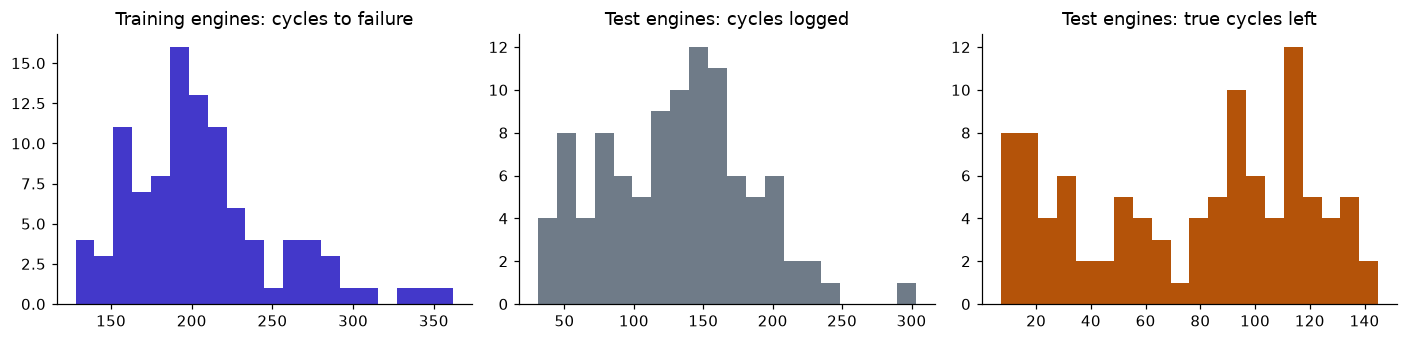

{'count': 100.0, 'mean': 206.3, 'std': 46.3, 'min': 128.0, '25%': 177.0, '50%': 199.0, '75%': 229.2, 'max': 362.0}


In [2]:
life = train.groupby("unit")["cycle"].max()
seen = test.groupby("unit")["cycle"].max()
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
ax[0].hist(life, bins=20, color="#4338ca"); ax[0].set_title("Training engines: cycles to failure")
ax[1].hist(seen, bins=20, color="#6f7b88"); ax[1].set_title("Test engines: cycles logged")
ax[2].hist(truth, bins=20, color="#b45309"); ax[2].set_title("Test engines: true cycles left")
plt.tight_layout(); plt.show()
print(life.describe().round(1).to_dict())

## 2. Which sensors move with wear

In [3]:
spread = train.drop(columns=["unit", "cycle"]).std().sort_values()
print(spread.round(5).head(10))
flat = [c for c in spread.index if spread[c] < 2e-3 or c.startswith("op")]
print("dropped:", flat)

s1     0.00000
op3    0.00000
s10    0.00000
s19    0.00000
s18    0.00000
s16    0.00000
s5     0.00000
op2    0.00029
s6     0.00139
op1    0.00219
dtype: float64
dropped: ['s1', 'op3', 's10', 's19', 's18', 's16', 's5', 'op2', 's6', 'op1']


The three operating settings and sensors 1, 5, 6, 10, 16, 18 and 19 are constant or nearly so in FD001 (one operating
condition). That leaves 14 sensors.

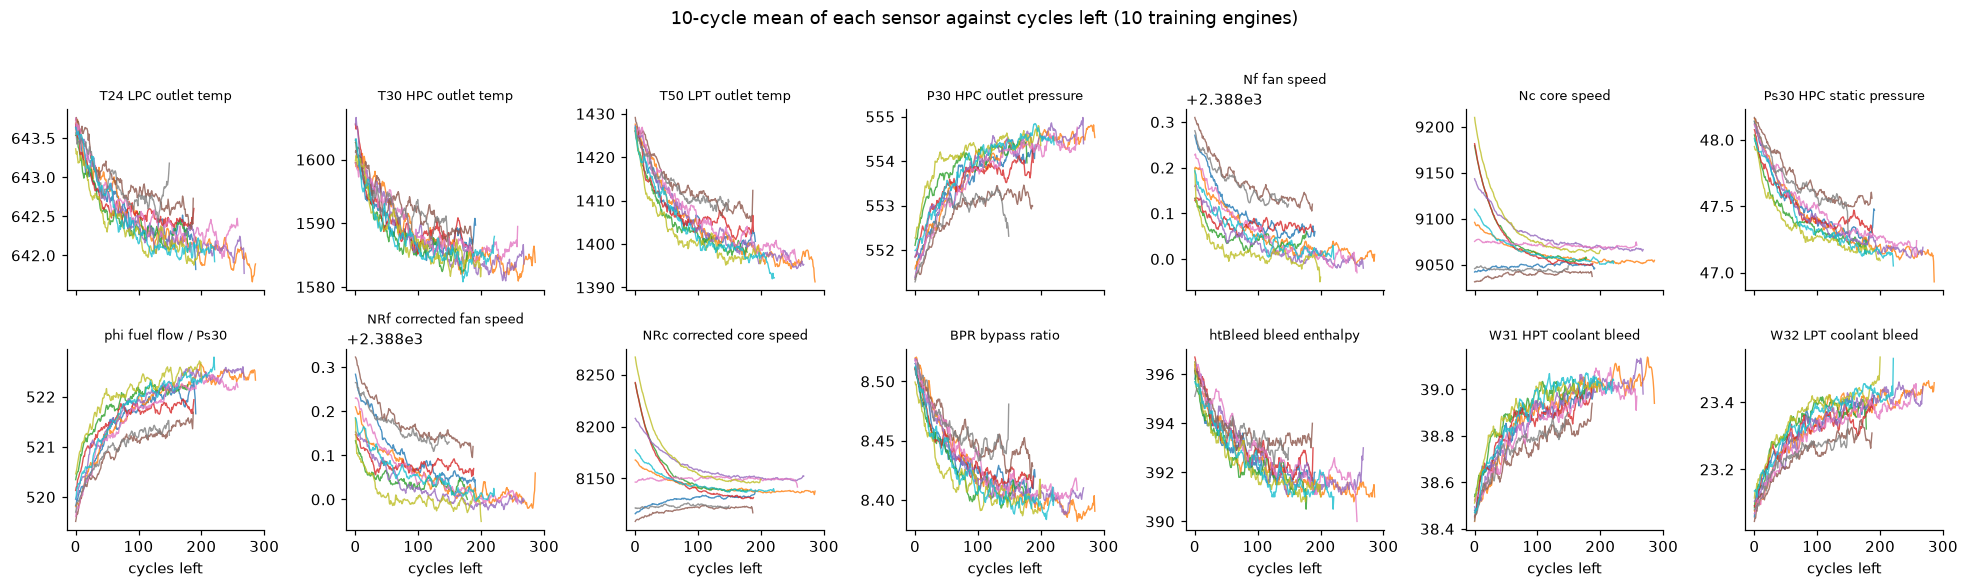

In [4]:
SENS = ["s2", "s3", "s4", "s7", "s8", "s9", "s11", "s12", "s13", "s14", "s15", "s17", "s20", "s21"]
NAMES = {"s2": "T24 LPC outlet temp", "s3": "T30 HPC outlet temp", "s4": "T50 LPT outlet temp", "s7": "P30 HPC outlet pressure",
         "s8": "Nf fan speed", "s9": "Nc core speed", "s11": "Ps30 HPC static pressure", "s12": "phi fuel flow / Ps30",
         "s13": "NRf corrected fan speed", "s14": "NRc corrected core speed", "s15": "BPR bypass ratio",
         "s17": "htBleed bleed enthalpy", "s20": "W31 HPT coolant bleed", "s21": "W32 LPT coolant bleed"}
train["rul"] = train.groupby("unit")["cycle"].transform("max") - train["cycle"]

fig, axes = plt.subplots(2, 7, figsize=(18, 5.2), sharex=True)
for ax, s in zip(axes.flat, SENS):
    for u in range(1, 11):
        e = train[train.unit == u]
        ax.plot(e["rul"], e[s].rolling(10, min_periods=1).mean(), lw=.9, alpha=.8)
    ax.set_title(NAMES[s], fontsize=8.5); ax.invert_xaxis()
for ax in axes[1]: ax.set_xlabel("cycles left")
plt.suptitle("10-cycle mean of each sensor against cycles left (10 training engines)", y=1.02)
plt.tight_layout(); plt.show()

Every sensor stays flat for most of an engine's life and then bends in the last 100 or so cycles, up for
temperatures, pressures at the outlet, bypass ratio and bleed enthalpy, down for P30, phi and the coolant bleeds. Two
consequences shape the model:

- **Far from failure the sensors carry almost no information** about how far away it is, so the target is capped.
- **The bend is the signal**: recent means and the recent slope matter more than single readings, which are noisy.

In [5]:
corr = train[SENS + ["rul"]].corr()["rul"].drop("rul").sort_values()
corr.rename(NAMES).round(3)

Ps30 HPC static pressure   -0.696
T50 LPT outlet temp        -0.679
BPR bypass ratio           -0.643
T24 LPC outlet temp        -0.606
htBleed bleed enthalpy     -0.606
T30 HPC outlet temp        -0.585
Nf fan speed               -0.564
NRf corrected fan speed    -0.563
Nc core speed              -0.390
NRc corrected core speed   -0.307
W31 HPT coolant bleed       0.629
W32 LPT coolant bleed       0.636
P30 HPC outlet pressure     0.657
phi fuel flow / Ps30        0.672
Name: rul, dtype: float64

## 3. Target: remaining life, capped at 125

Early in life an engine with 200 cycles left looks the same as one with 125. Asking a model to tell them apart only
adds noise, so the target is `min(RUL, 125)`, the usual choice for FD001. The model then reads "125" as "healthy,
125 or more". Test scores below cap the true RUL the same way (the uncapped RMSE is reported too).

In [6]:
CAP = 125
y_all = train["rul"].clip(upper=CAP)
print(f"rows at the cap: {(train.rul >= CAP).mean():.0%}")

rows at the cap: 39%


## 4. Features from each engine's own history

For every cycle, using only that engine's cycles up to it (no look-ahead, no mixing of engines):

- the raw reading of each of the 14 sensors,
- its 10-cycle and 30-cycle means (with fewer cycles at the start, the mean of what there is),
- its least-squares slope over the last 20 cycles (from 3 cycles on),
- the cycles flown so far.

57 features in all. The slope is computed with rolling sums, so features for all 20,631 training rows take a few
seconds.

In [7]:
def slope(x, k=20):
    t = pd.Series(np.arange(len(x), dtype=float), index=x.index)
    mean = lambda s: s.rolling(k, min_periods=3).mean()
    return ((mean(t * x) - mean(t) * mean(x)) / (mean(t * t) - mean(t) ** 2)).fillna(0.0)


FEATURES = ["cycle"] + [f for s in SENS for f in (s, f"{s}_m10", f"{s}_m30", f"{s}_sl")]


def make_features(history):
    h = history.sort_values(["unit", "cycle"], kind="stable")
    g = h.groupby("unit", sort=False)
    out = {"unit": h["unit"], "cycle": h["cycle"].astype(float)}
    for s in SENS:
        out[s] = h[s].astype(float)
        for k in (10, 30):
            out[f"{s}_m{k}"] = g[s].transform(lambda x, k=k: x.rolling(k, min_periods=1).mean())
        out[f"{s}_sl"] = g[s].transform(slope)
    return pd.DataFrame(out)[["unit"] + FEATURES]


F = make_features(train)
X, y, groups = F[FEATURES], y_all.to_numpy(), F["unit"].to_numpy()
Ft = make_features(test)
X_test = Ft.groupby("unit").tail(1)[FEATURES]
print(X.shape, X_test.shape)

# checks: a feature at cycle t is the same whether or not later cycles exist, and engines never mix
one = test[test.unit == 7]
assert make_features(one).head(40).reset_index(drop=True).equals(make_features(one.head(40)).reset_index(drop=True))
both = make_features(test[test.unit.isin([1, 2])])
assert both[both.unit == 2].reset_index(drop=True).equals(make_features(test[test.unit == 2]).reset_index(drop=True))
print("no look-ahead, no mixing: ok")

(20631, 57) (100, 57)


no look-ahead, no mixing: ok


## 5. Validation: folds grouped by engine

Neighbouring cycles of one engine are nearly identical. If folds shuffle rows, the model is tested on cycles whose
neighbours it trained on, and the score is too good. The comparison below uses the same LightGBM both ways.

In [8]:
def lgbm():
    return LGBMRegressor(n_estimators=600, learning_rate=0.03, num_leaves=31, min_child_samples=40, subsample=0.8,
                         subsample_freq=1, colsample_bytree=0.7, verbose=-1, random_state=42)


def cv_oof(est, splitter):
    oof = np.zeros(len(y))
    for a, b in splitter:
        oof[b] = est.fit(X.iloc[a], y[a]).predict(X.iloc[b])
    return np.clip(oof, 0, CAP)


rmse = lambda a, b: float(np.sqrt(np.mean((a - b) ** 2)))
folds = list(GroupKFold(n_splits=5).split(X, y, groups))
shuffled = rmse(cv_oof(lgbm(), KFold(5, shuffle=True, random_state=42).split(X)), y)
grouped = rmse(cv_oof(lgbm(), folds), y)
print(f"shuffled rows: CV RMSE {shuffled:.2f}   grouped by engine: CV RMSE {grouped:.2f}")

shuffled rows: CV RMSE 7.49   grouped by engine: CV RMSE 13.58


Shuffled folds report about half the real error (7.5 against 13.6 cycles). Everything below uses the grouped folds.

## 6. Candidates

In [9]:
def nasa(d):
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))


def test_scores(pred):
    tc = np.minimum(truth, CAP); d = pred - tc
    return {"test_rmse": rmse(pred, tc), "test_rmse_uncapped": rmse(pred, truth), "test_mae": float(np.abs(d).mean()),
            "test_nasa": nasa(d), "test_late_20": int((d > 20).sum())}


candidates = {
    "Ridge regression": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Random forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=5, max_features=0.33, n_jobs=-1, random_state=42),
    "Histogram gradient boosting": HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, random_state=42),
    "LightGBM": lgbm(),
}
base = np.zeros(len(y))
for a, b in folds:
    base[b] = y[a].mean()
rows = [{"model": "Baseline: average remaining life", "cv_rmse": rmse(base, y), **test_scores(np.full(len(truth), y.mean()))}]
oofs, fitted = {}, {}
for name, est in candidates.items():
    oofs[name] = cv_oof(est, folds)
    fitted[name] = est.fit(X, y)
    rows.append({"model": name, "cv_rmse": rmse(oofs[name], y), **test_scores(np.clip(est.predict(X_test), 0, CAP))})
table = pd.DataFrame(rows).set_index("model")
table.round(2)

,cv_rmse,test_rmse,test_rmse_uncapped,test_mae,test_nasa,test_late_20
model,,,,,,
Baseline: average remaining life,41.67,41.94,43.07,34.83,33354.47,41
Ridge regression,15.46,15.71,17.14,12.94,365.18,11
Random forest,14.07,14.43,15.67,10.46,348.16,8
Histogram gradient boosting,13.78,14.30,15.54,10.33,370.76,7
LightGBM,13.58,13.79,15.07,9.84,338.19,8


LightGBM has the lowest cross-validation RMSE, so it is the model; its test scores are read once, after the choice.
The three tree models are within half a cycle of each other. All of them are about three times better than the
baseline. Ridge regression trails because the sensors bend near the end of life rather than drift in a straight line.

{'test_rmse': 13.79, 'test_rmse_uncapped': 15.07, 'test_mae': 9.84, 'test_nasa': 338.19, 'test_late_20': 8} R2 0.882


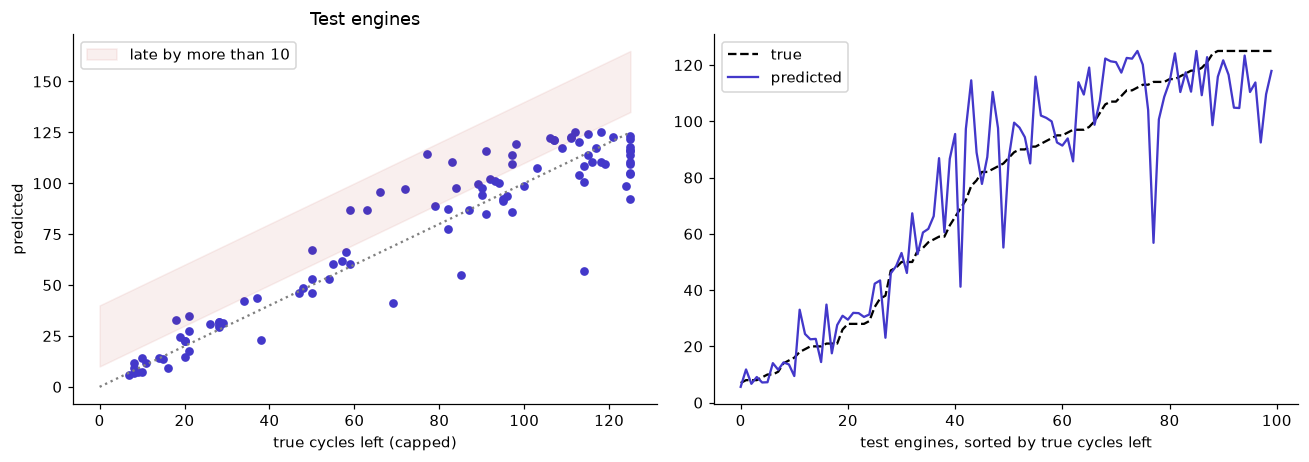

In [10]:
best = table.drop(index="Baseline: average remaining life")["cv_rmse"].idxmin()
assert best == "LightGBM"
model, oof = fitted[best], oofs[best]
pred = np.clip(model.predict(X_test), 0, CAP)
tc = np.minimum(truth, CAP)
print({k: round(v, 2) for k, v in test_scores(pred).items()}, "R2", round(1 - np.sum((pred - tc) ** 2) / np.sum((tc - tc.mean()) ** 2), 3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
ax[0].scatter(tc, pred, s=22, color="#4338ca"); ax[0].plot([0, CAP], [0, CAP], ls=":", c="grey")
ax[0].fill_between([0, CAP], [10, CAP + 10], [40, CAP + 40], color="#b42318", alpha=.07, label="late by more than 10")
ax[0].set_xlabel("true cycles left (capped)"); ax[0].set_ylabel("predicted"); ax[0].legend(); ax[0].set_title("Test engines")
order = np.argsort(tc)
ax[1].plot(tc[order], c="black", ls="--", label="true"); ax[1].plot(pred[order], c="#4338ca", label="predicted")
ax[1].set_xlabel("test engines, sorted by true cycles left"); ax[1].legend()
plt.tight_layout(); plt.show()

## 7. An 80% range from out-of-fold errors

Errors depend on where an engine is in its life, so the range comes from the cross-validation errors of cycles with
a similar prediction: the 10th and 90th percentile of `truth - prediction` in five bands of the prediction.

In [11]:
EDGES = [25, 50, 75, 100]
res = y - oof
band = np.digitize(oof, EDGES)
quant = [np.percentile(res[band == i], [10, 90]).round(2).tolist() for i in range(len(EDGES) + 1)]
print(pd.DataFrame(quant, columns=["low", "high"], index=["<25", "25-50", "50-75", "75-100", "100+"]))

def bounds(p):
    b = np.digitize(p, EDGES)
    return np.clip(p + np.array([quant[i][0] for i in b]), 0, None), p + np.array([quant[i][1] for i in b])

lo_cv, hi_cv = bounds(oof)
lo, hi = bounds(pred)
print(f"coverage: cross-validation {((y >= lo_cv) & (y <= hi_cv)).mean():.1%}, test engines {((tc >= lo) & (tc <= hi)).mean():.1%}")

          low   high
<25     -4.39   4.43
25-50  -10.77  10.13
50-75  -18.50  21.09
75-100 -24.61  32.70
100+   -15.46  12.83
coverage: cross-validation 80.0%, test engines 77.0%


The range is about ±5 cycles near failure and widest in mid-life. It holds 80% in cross-validation by construction
and 77% on the 100 test engines, which stop at random points of their life.

## 8. Late errors and maintenance lanes

A late prediction says an engine has more life than it does. Out of fold, the model is late on average with 26 to
100 cycles left: wear has started but the sensors have barely moved, so the engine still looks healthy.

In [12]:
d = oof - y
bands = pd.cut(y, [-1, 25, 50, 75, 100, CAP], labels=["0-25", "26-50", "51-75", "76-100", "101-125"])
pd.DataFrame({"band": bands, "mean error (late +)": d, "mean abs error": np.abs(d)}).groupby("band", observed=False).mean().round(2)

,mean error (late +),mean abs error
band,,
0-25,1.56,3.31
26-50,4.90,8.50
51-75,8.86,14.37
76-100,6.49,14.53
101-125,-6.77,8.28


So the lanes use the **safe life**, the low end of the 80% range, instead of the prediction: **ground** below 20
cycles of safe life, **plan** a shop visit below 50, otherwise **fly**. These lines are a maintenance policy chosen
before looking at the test engines; the app lets you move them.

In [13]:
POLICY = {"ground": 20, "plan": 50}
lane = lambda low: np.where(low < POLICY["ground"], "Ground", np.where(low < POLICY["plan"], "Plan", "Fly"))
truth_band = lambda t: pd.cut(t, [-1, 20, 50, 10_000], labels=["0-20 left", "21-50 left", "over 50 left"])
print("Test engines (100)")
print(pd.crosstab(truth_band(truth), lane(lo)).reindex(columns=["Ground", "Plan", "Fly"], fill_value=0))
print()
print("Training engines, every cycle, held out")
print(pd.crosstab(truth_band(train["rul"].to_numpy()), lane(lo_cv)).reindex(columns=["Ground", "Plan", "Fly"], fill_value=0))

Test engines (100)
col_0         Ground  Plan  Fly
row_0                          
0-20 left         14     2    0
21-50 left         5    12    0
over 50 left       0     8   59

Training engines, every cycle, held out
col_0         Ground  Plan    Fly
row_0                            
0-20 left       2072    28      0
21-50 left       828  2033    139
over 50 left       1  1374  14156


No engine within 20 cycles of failure is cleared to fly, on the test engines or on any held-out training cycle. The
cost is engines grounded or booked early: shop visits that come before they are strictly needed.

In [14]:
contrib = model.predict(X_test.iloc[[33]], pred_contrib=True)[0]
parts = pd.Series(contrib[:-1], index=FEATURES)
by_sensor = pd.Series({"cycles flown": parts["cycle"]} | {NAMES[s]: parts[[f for f in FEATURES if f == s or f.startswith(s + "_")]].sum() for s in SENS})
print(f"engine 34: average engine {contrib[-1]:.1f} + readings {parts.sum():+.1f} = {contrib[-1] + parts.sum():.1f} cycles (true {truth[33]})")
by_sensor.sort_values(key=abs, ascending=False).head(8).round(1)

engine 34: average engine 86.8 + readings -81.2 = 5.6 cycles (true 7)


T50 LPT outlet temp        -18.2
BPR bypass ratio           -12.4
Ps30 HPC static pressure   -10.8
T24 LPC outlet temp        -10.2
T30 HPC outlet temp         -5.6
cycles flown                -5.0
NRf corrected fan speed     -4.5
W32 LPT coolant bleed       -3.2
dtype: float64

LightGBM's own contributions (TreeSHAP) explain each prediction: they add up from the average engine's estimate to
this engine's. For engine 34, the LPT outlet temperature (T50), bypass ratio and HPC static pressure take the most
life away.

## 9. The first version's clipping, measured

`train.clip(upper=125)` caps every column of the frame. On the raw training data:

In [15]:
clipped = train[SENS].clip(upper=125)
print("sensors that become constant after clipping every column:", [NAMES[s] for s in SENS if clipped[s].nunique() == 1])

sensors that become constant after clipping every column: ['T24 LPC outlet temp', 'T30 HPC outlet temp', 'T50 LPT outlet temp', 'P30 HPC outlet pressure', 'Nf fan speed', 'Nc core speed', 'phi fuel flow / Ps30', 'NRf corrected fan speed', 'NRc corrected core speed', 'htBleed bleed enthalpy']


Ten of the fourteen sensors, including T50 (the LPT outlet temperature, the one the model above relies on most), carried no information in the first version.

## 10. Save the model

In [16]:
gain = pd.Series(model.booster_.feature_importance("gain"), index=FEATURES)
imp = {"cycle": float(gain["cycle"])} | {s: float(gain[[f for f in FEATURES if f == s or f.startswith(s + "_")]].sum()) for s in SENS}
total = sum(imp.values())
out = Path("model"); out.mkdir(exist_ok=True)
joblib.dump(model, out / "turbolife_lgbm.joblib", compress=3)
meta = {"model": "LightGBM regressor (600 trees, learning rate 0.03, 31 leaves)", "cap": CAP, "features": FEATURES,
        "policy": POLICY, "range": {"edges": EDGES, "quantiles": quant},
        "comparison": table.reset_index().to_dict(orient="records"),
        "test": test_scores(pred) | {"coverage": float(((tc >= lo) & (tc <= hi)).mean())},
        "importance": {k: v / total for k, v in imp.items()}}
(out / "metadata.json").write_text(json.dumps(meta, indent=2))
print(sorted(p.name for p in out.iterdir()))

['metadata.json', 'turbolife_lgbm.joblib']


The app ([TurboLife](https://turbolife-engine-health-application.streamlit.app/)) ships the same model, rebuilt by its
`train.py` from the same three files.